# Обзор FPS, задержки и памяти

Запустите все ячейки после сохранения результатов в [ноутбуке измерений](fps_measure.ipynb). Для каждой модели, устройства, режима и частоты потока показан последний сохранённый замер. Direct и stream могут относиться к разным сессиям, весам и входам. Источники и настройки приведены в подробной таблице.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

notebook_dir = Path.cwd()
if not (notebook_dir / 'scripts' / 'benchmark').is_dir():
    notebook_dir = notebook_dir / 'manual_notebooks'
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

from scripts.benchmark.review import latest_measurements, simple_table, full_table, comparison_figures

RESULTS_ROOT = notebook_dir.parent / 'experiments' / 'benchmarks'
measurements = latest_measurements(RESULTS_ROOT)
if not measurements:
    print(f'No completed measurements found in {RESULTS_ROOT}')

## Краткая таблица

FPS равен числу обработанных кадров, делённому на длительность окна. Для потока он зависит от частоты подачи. RAM — выборочный пик RSS процесса, GPU — пиковая выделенная память PyTorch. Оба пика получены в отдельном проходе измерения памяти. Прочерк означает отсутствие значения.

Model tensors — объём параметров и буферов при загрузке до прогрева. Он зависит от точности и выбранных весов. Для прежних замеров и семантического режима SAM3 поле пустое.

In [2]:
if measurements:
    with pd.option_context('display.max_columns', None, 'display.max_rows', None):
        display(simple_table(measurements).style.format(precision=2, na_rep='—'))

## Подробная таблица

Одна строка на замер. Поля `probe_*` относятся к отдельному проходу памяти. Показатели RSS и CUDA без префикса относятся к окну FPS или к исходному уровню процесса. Поля с `bytes` указаны в байтах. В `source` записан путь к исходному JSON, а в `worker_inputs` — порядок, пути и контрольные суммы входов.

Поля model_*_bytes описывают хранилища тензоров до первого предсказания.

In [3]:
if measurements:
    with pd.option_context('display.max_columns', None, 'display.max_rows', None):
        display(full_table(measurements))

,model_id,device,mode,input_fps,processed,elapsed_s,processing_fps,prediction_ms_mean,prediction_ms_median,prediction_ms_p95,prediction_ms_p99,rss_warm_bytes,rss_sampled_peak_bytes,cuda_allocated_bytes_warm,cuda_reserved_bytes_warm,cuda_allocated_bytes_peak,cuda_reserved_bytes_peak,rss_baseline_bytes,source,saved_repeat,worker_schema_version,worker_status,worker_backend,worker_checkpoint,worker_checkpoint_sha256,worker_inputs,worker_config,worker_options,worker_prompts,worker_notes,worker_platform,worker_processor,worker_python,worker_packages,worker_torch_threads,worker_torch_interop_threads,worker_cuda_version,worker_cudnn_version,worker_cuda_device,worker_float32_matmul_precision,worker_cudnn_benchmark,worker_cudnn_allow_tf32,worker_cuda_matmul_allow_tf32,worker_rss_baseline_bytes,worker_cuda_baseline,worker_schedule,frame_latency_ms_mean,frame_latency_ms_median,frame_latency_ms_p95,frame_latency_ms_p99,generated,consumed,dropped,generation_fps,drop_rate,probe_rss_warm_bytes,probe_rss_sampled_peak_bytes,probe_cuda_allocated_bytes_warm,probe_cuda_reserved_bytes_warm,probe_cuda_allocated_bytes_peak,probe_cuda_reserved_bytes_peak,worker_runtime
0,rf-detr-m,cpu,direct,NaN,49,30.492949,1.606929,622.293791,622.929742,643.567186,652.416865,1333039104,1334001664,None,None,None,None,596111360,/home/natsusa/academic/tobacco-article/experim...,1.0,1,completed,rfdetr,/home/natsusa/academic/tobacco-article/weights...,f98d7caa91ed6a09ae56329a0740739c7eed88568c4949...,[{'path': '/home/natsusa/academic/tobacco-arti...,"{'warmup_frames': 30, 'duration_s': 30, 'repet...",{'conf': 0.25},None,,Linux-7.2.4-arch1-2-x86_64-with-glibc2.44,,3.14.7,"{'torch': '2.14.1', 'torchvision': '0.29.1', '...",6,6,13.0,92400,None,highest,False,True,False,596111360,"{'cuda_allocated_bytes': None, 'cuda_reserved_...","[[1, None]]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,rf-detr-m,cpu,stream,10.0,48,30.243969,1.587093,630.060915,628.143377,635.599001,672.425202,1338171392,1338191872,None,None,None,None,596103168,/home/natsusa/academic/tobacco-article/experim...,1.0,1,completed,rfdetr,/home/natsusa/academic/tobacco-article/weights...,f98d7caa91ed6a09ae56329a0740739c7eed88568c4949...,[{'path': '/home/natsusa/academic/tobacco-arti...,"{'warmup_frames': 30, 'duration_s': 30, 'repet...",{'conf': 0.25},None,,Linux-7.2.4-arch1-2-x86_64-with-glibc2.44,,3.14.7,"{'torch': '2.14.1', 'torchvision': '0.29.1', '...",6,6,13.0,92400,None,highest,False,True,False,596103168,"{'cuda_allocated_bytes': None, 'cuda_reserved_...","[[1, 20], [1, 60], [1, 30], [1, 10], [1, 300]]",680.325787,680.050904,724.820616,735.718716,303.0,48.0,254.0,10.018526,8.398369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rf-detr-m,cpu,stream,20.0,47,30.160427,1.558333,641.683612,641.934342,656.477364,658.157425,1332846592,1335345152,None,None,None,None,596103168,/home/natsusa/academic/tobacco-article/experim...,1.0,1,completed,rfdetr,/home/natsusa/academic/tobacco-article/weights...,f98d7caa91ed6a09ae56329a0740739c7eed88568c4949...,[{'path': '/home/natsusa/academic/tobacco-arti...,"{'warmup_frames': 30, 'duration_s': 30, 'repet...",{'conf': 0.25},None,,Linux-7.2.4-arch1-2-x86_64-with-glibc2.44,,3.14.7,"{'torch': '2.14.1', 'torchvision': '0.29.1', '...",6,6,13.0,92400,None,highest,False,True,False,596103168,"{'cuda_allocated_bytes': None, 'cuda_reserved_...","[[1, 20], [1, 60], [1, 30], [1, 10], [1, 300]]",667.043368,665.475441,693.165620,701.455248,604.0,47.0,556.0,20.026242,18.434752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,rf-detr-m,cpu,stream,30.0,46,30.356184,1.515342,659.894836,640.255013,742.719361,776.783505,1337389056,1337417728,None,None,None,None,596103168,/home/natsusa/academic/tobacco-article/experim...,1.0,1,completed,rfdetr,/home/natsusa/academic/tobacco-article/weights...,f98d7caa91ed6a09ae56329a0740739c7eed88568c4949...,[{'path': '/home/natsusa/academic/tobacco-arti...,"{'warmup_frames': 30, 'duration_s': 30, 'repet...",{'conf': 0.25},None,,Linux-7.2.4-arch1-2-x86_64-with-glibc2.44,,3.14.7,

## Графики по моделям

Слева — direct, справа — синтетический поток с указанной частотой подачи. Время отсчитывается от начала каждого замера. В режиме `binned` FPS рассчитывается по окнам шириной `FPS_BIN_SECONDS`, в режиме `instantaneous` — как обратный интервал между соседними завершениями кадров. Задержка показана для каждого завершённого кадра, пунктир включает ожидание в очереди потока. График памяти использует отсчёты внутри окна FPS. Для GPU ряд отображается только при наличии записанных отсчётов.

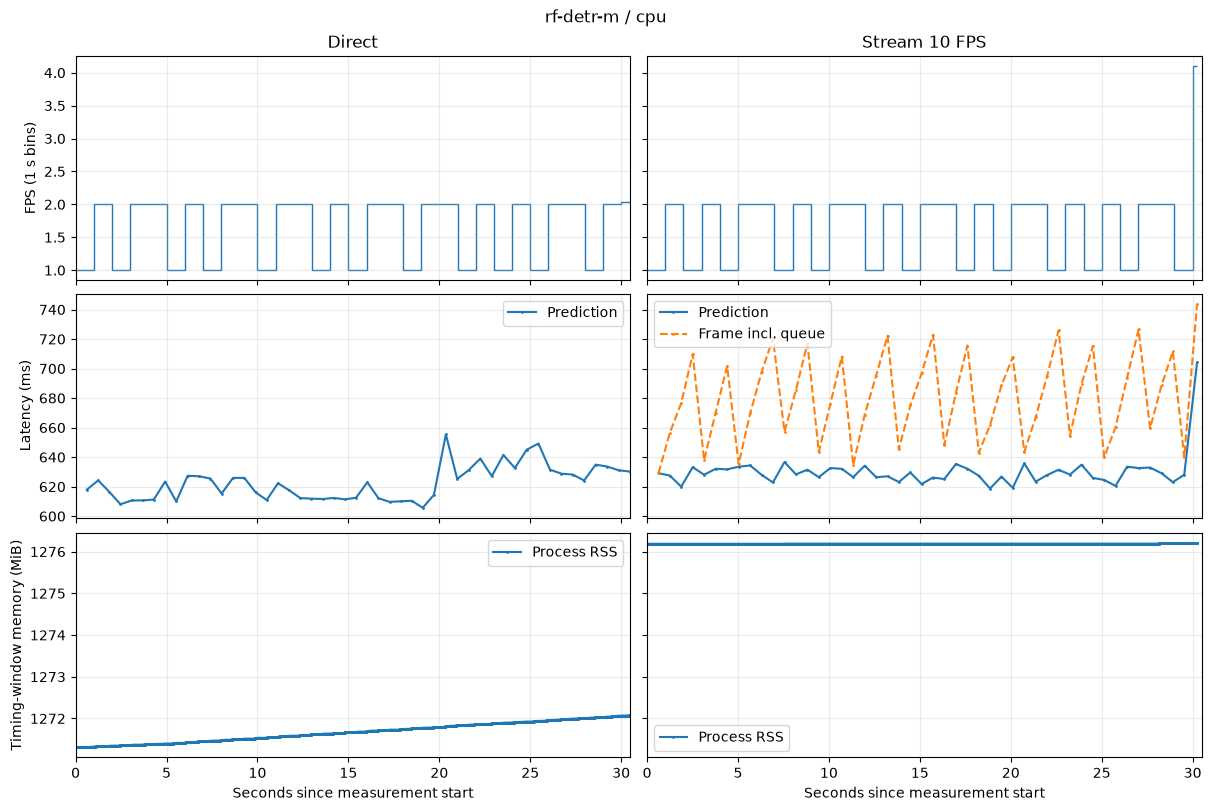

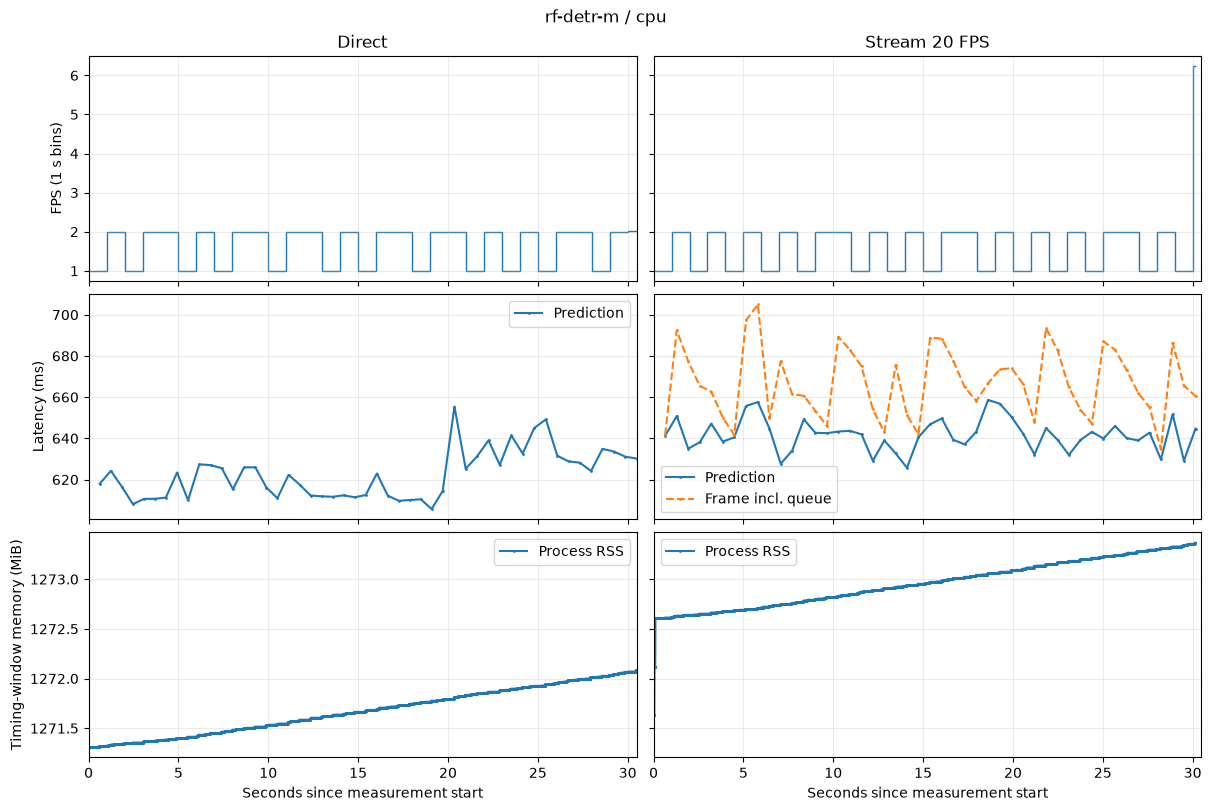

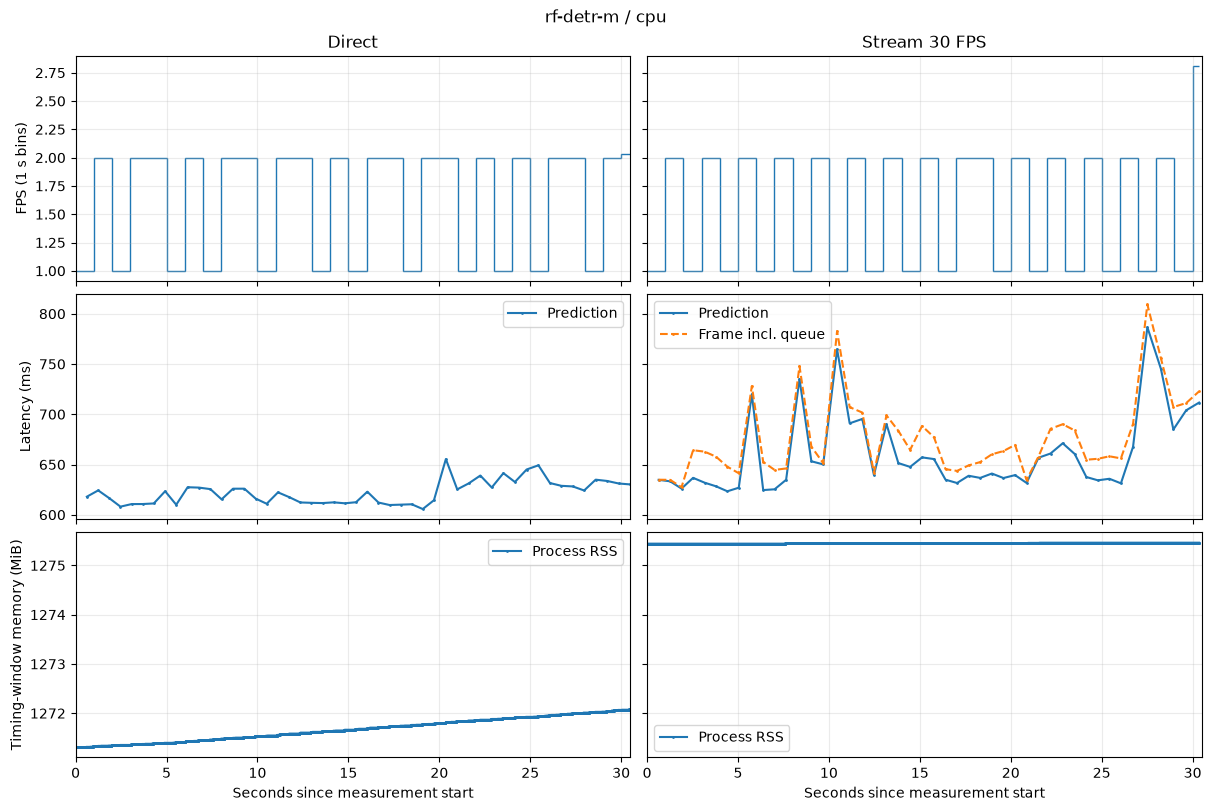

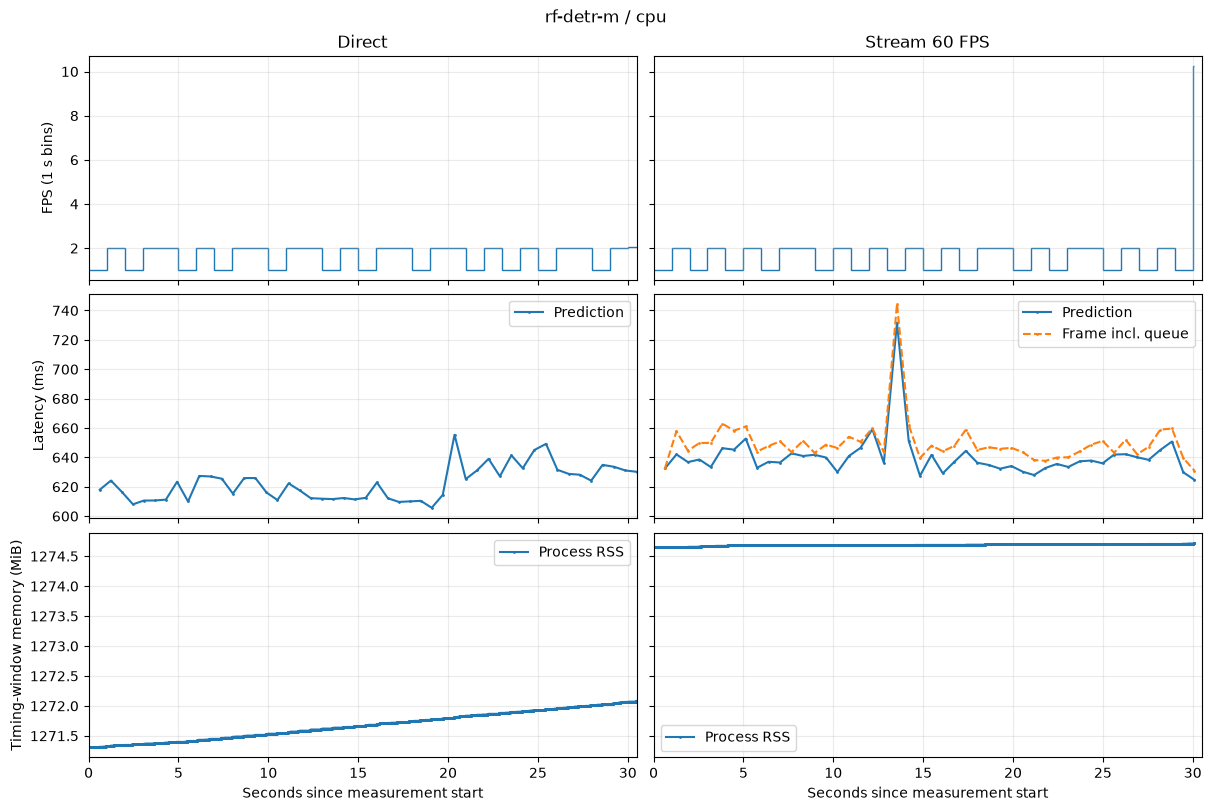

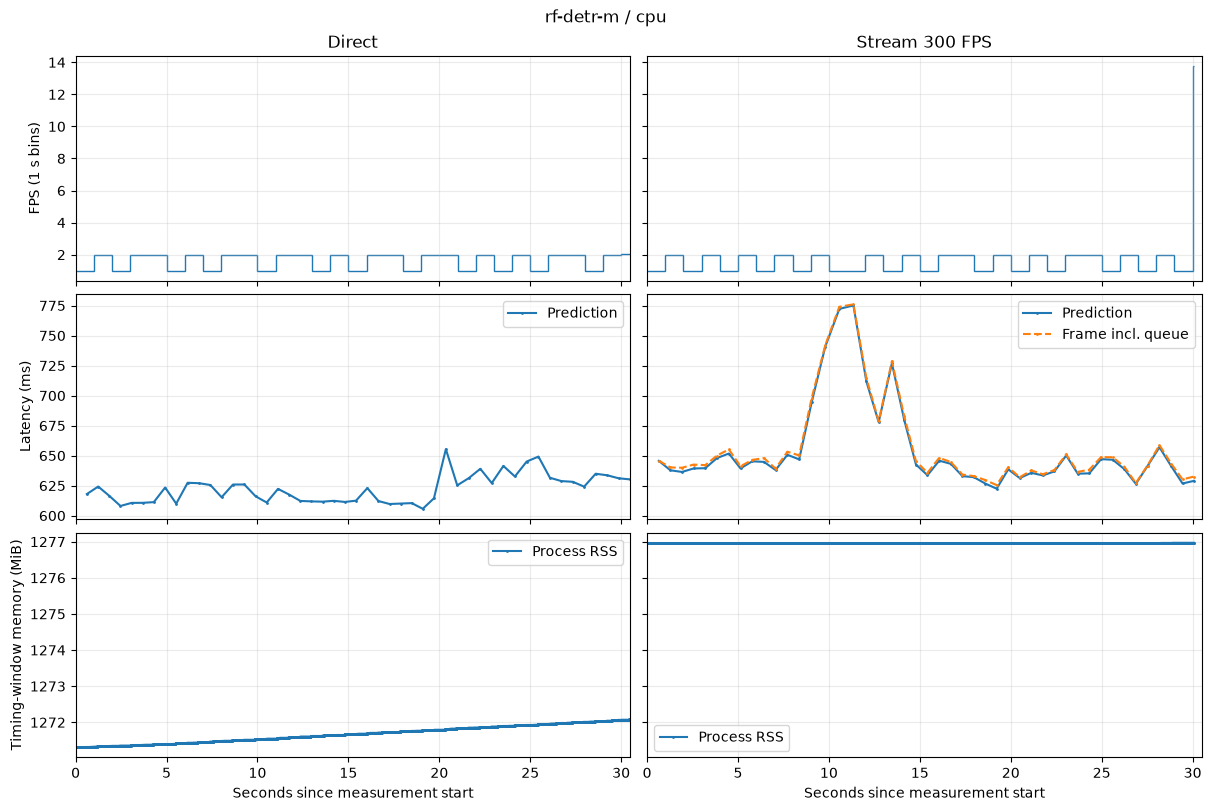

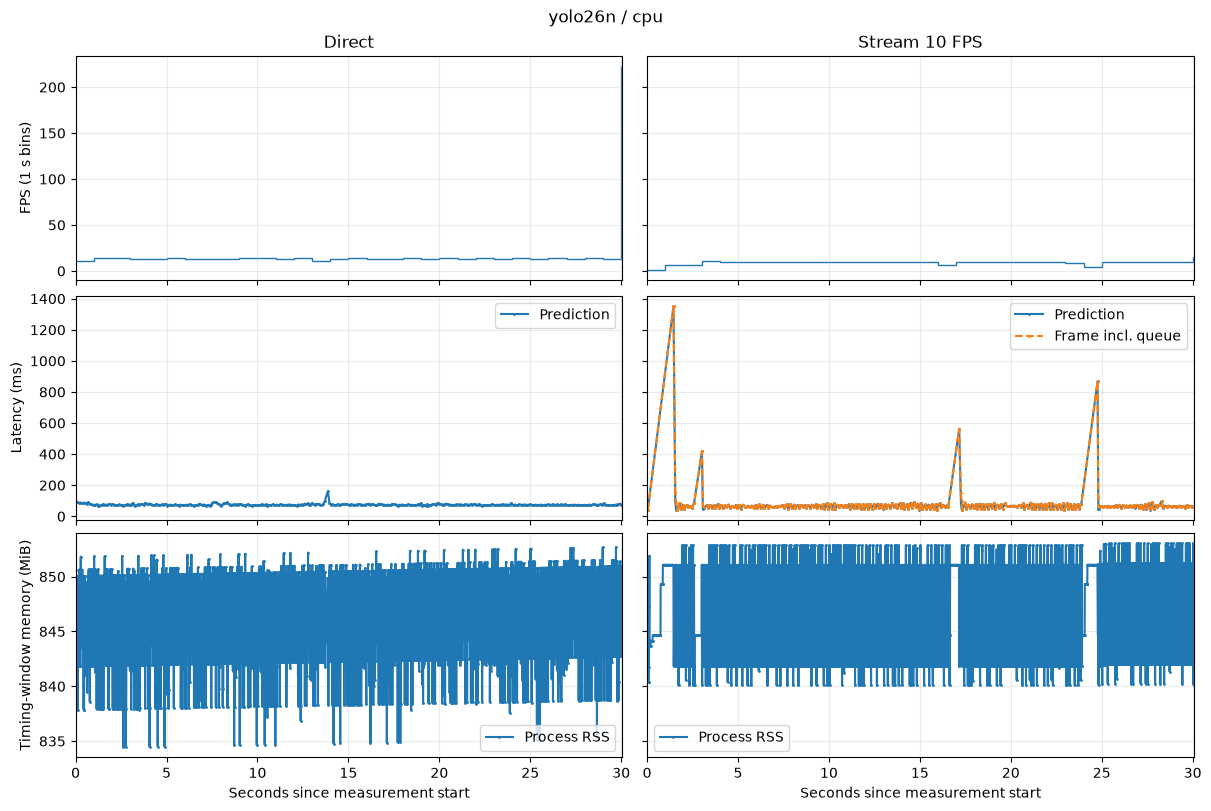

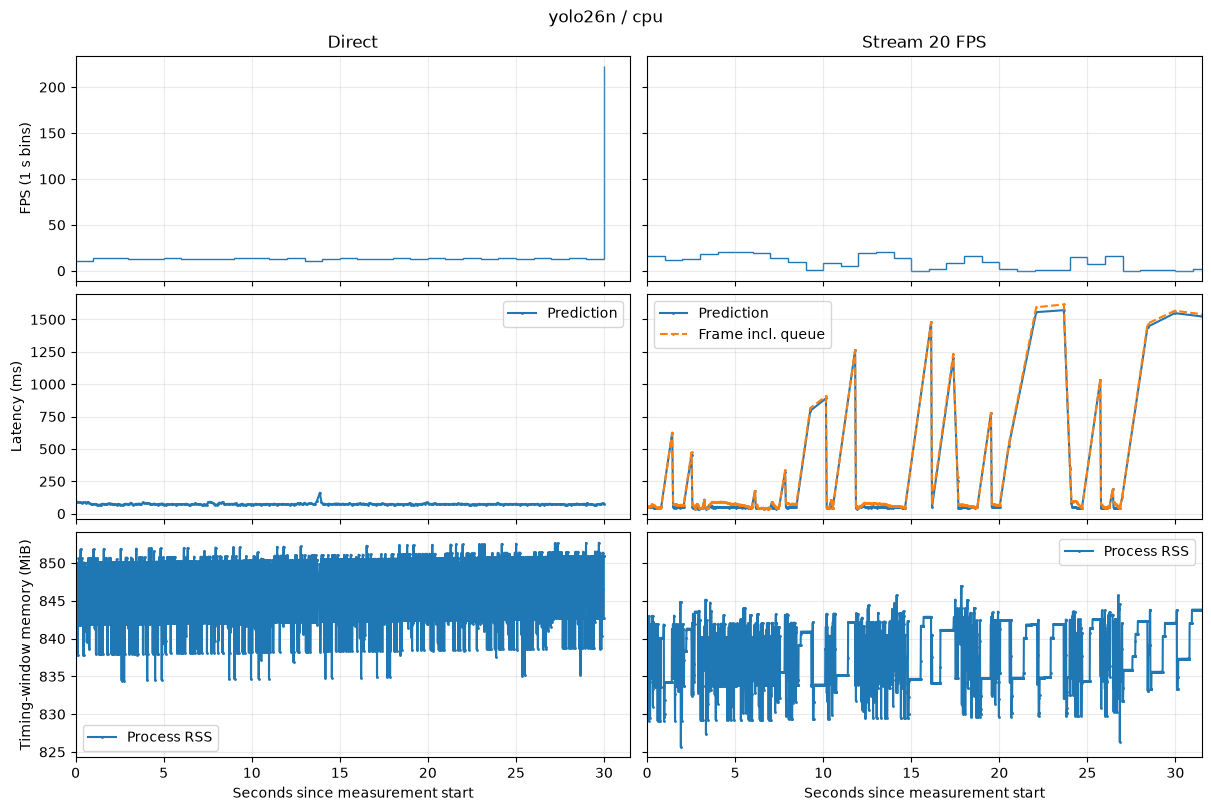

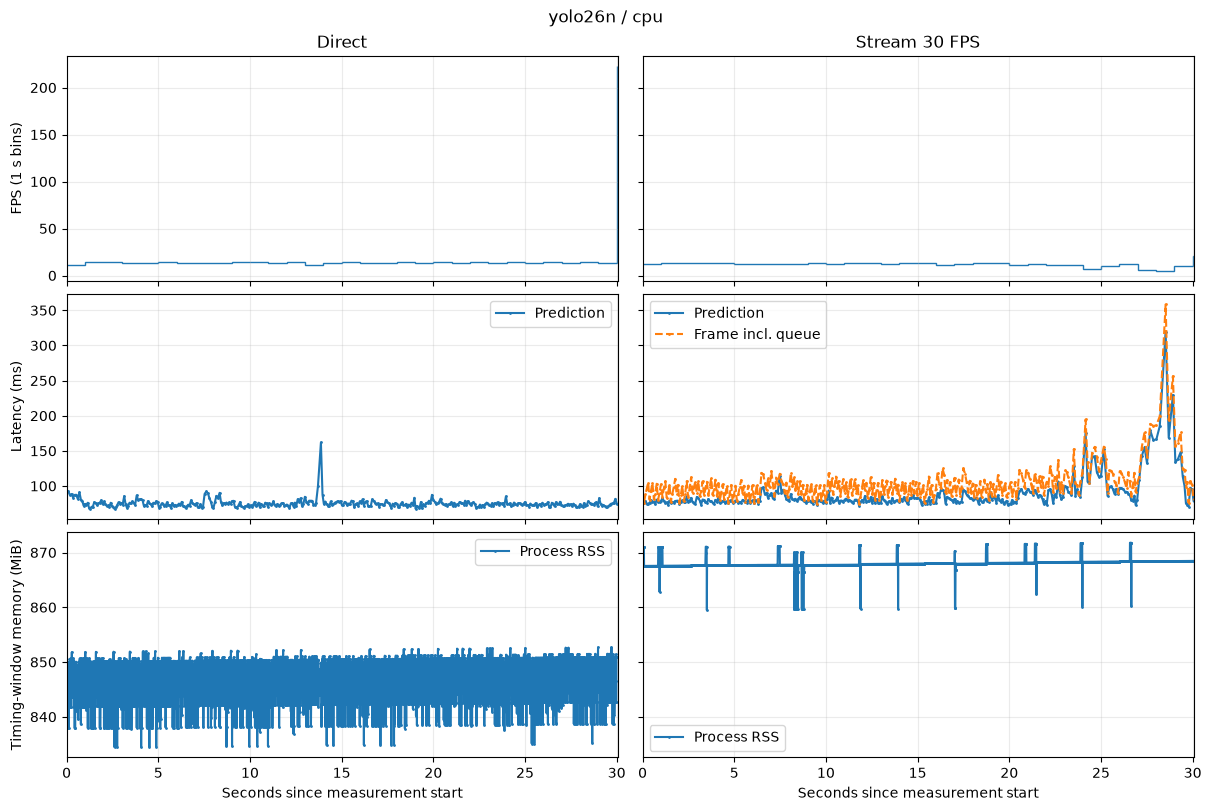

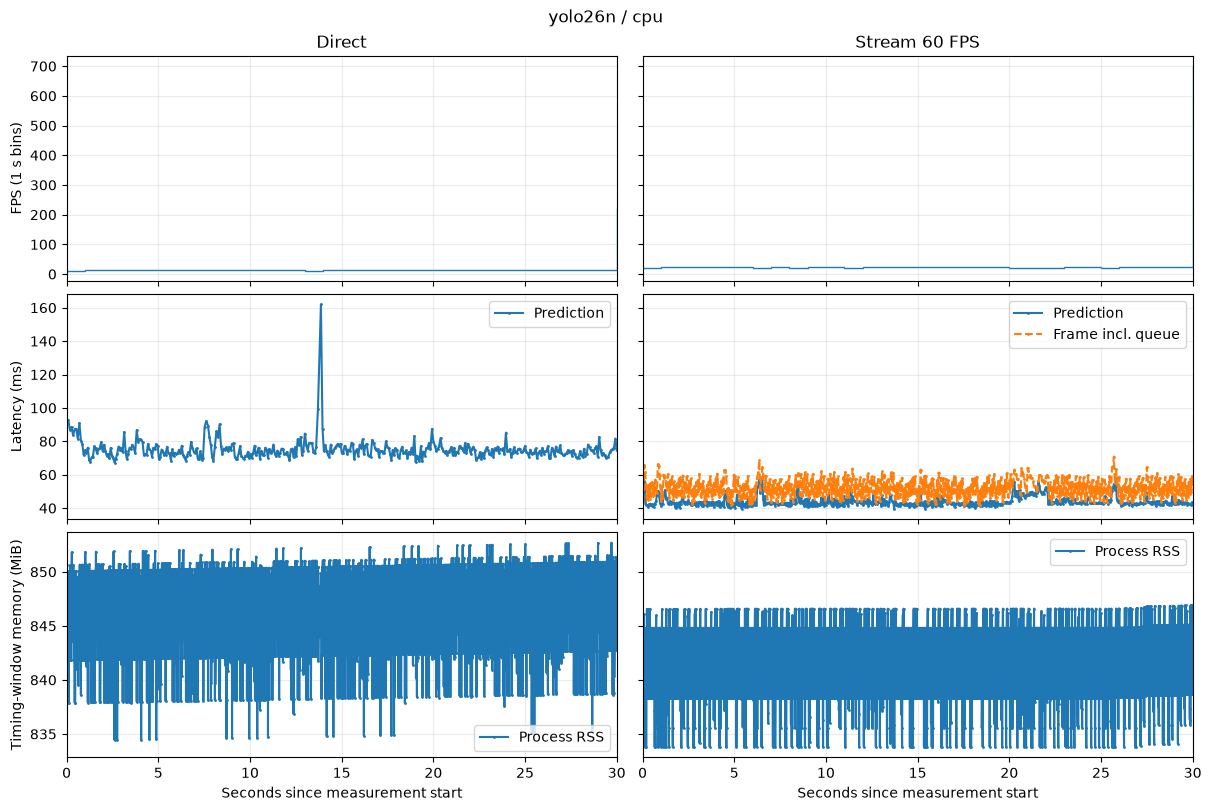

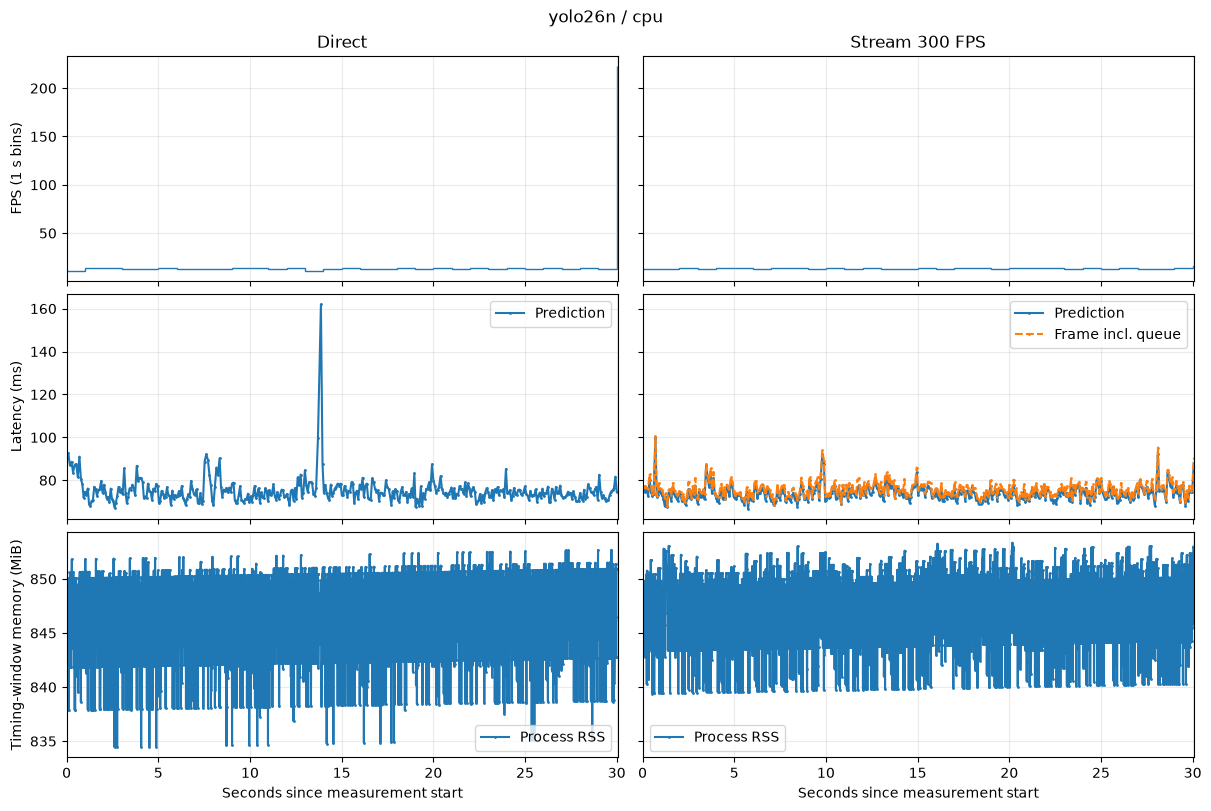

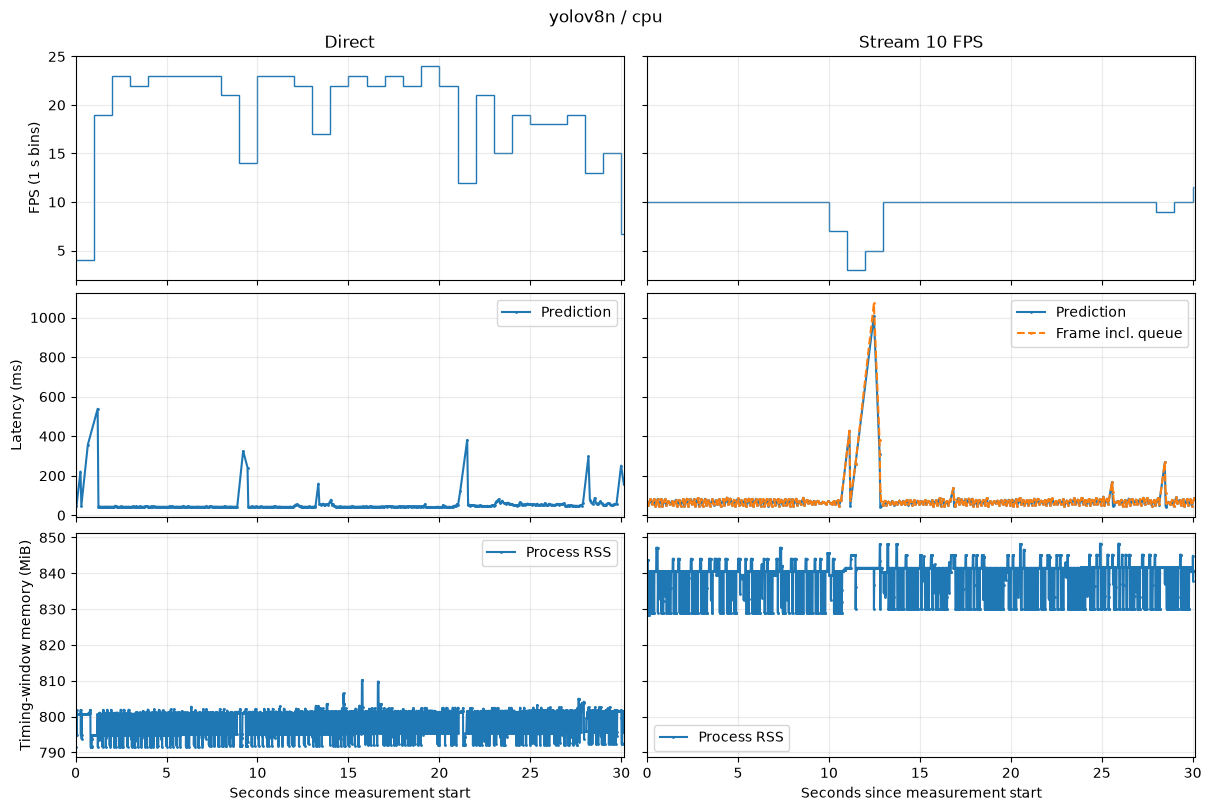

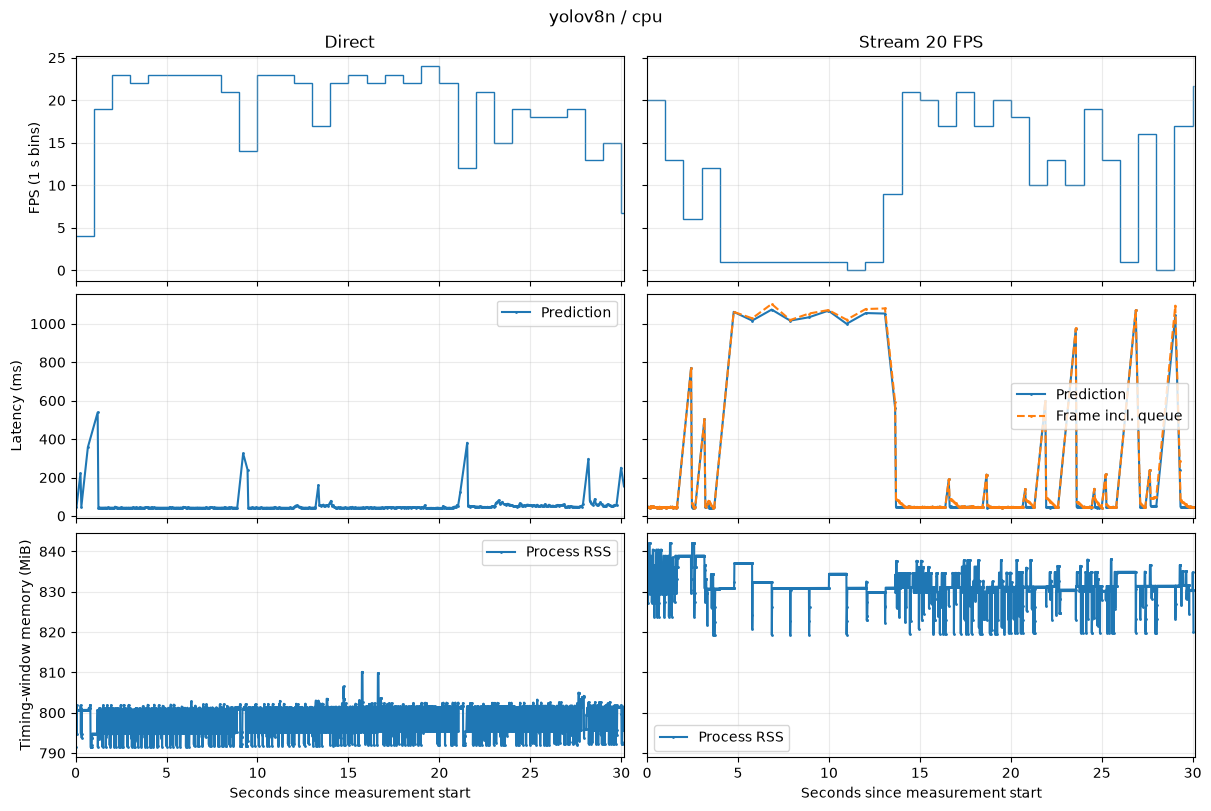

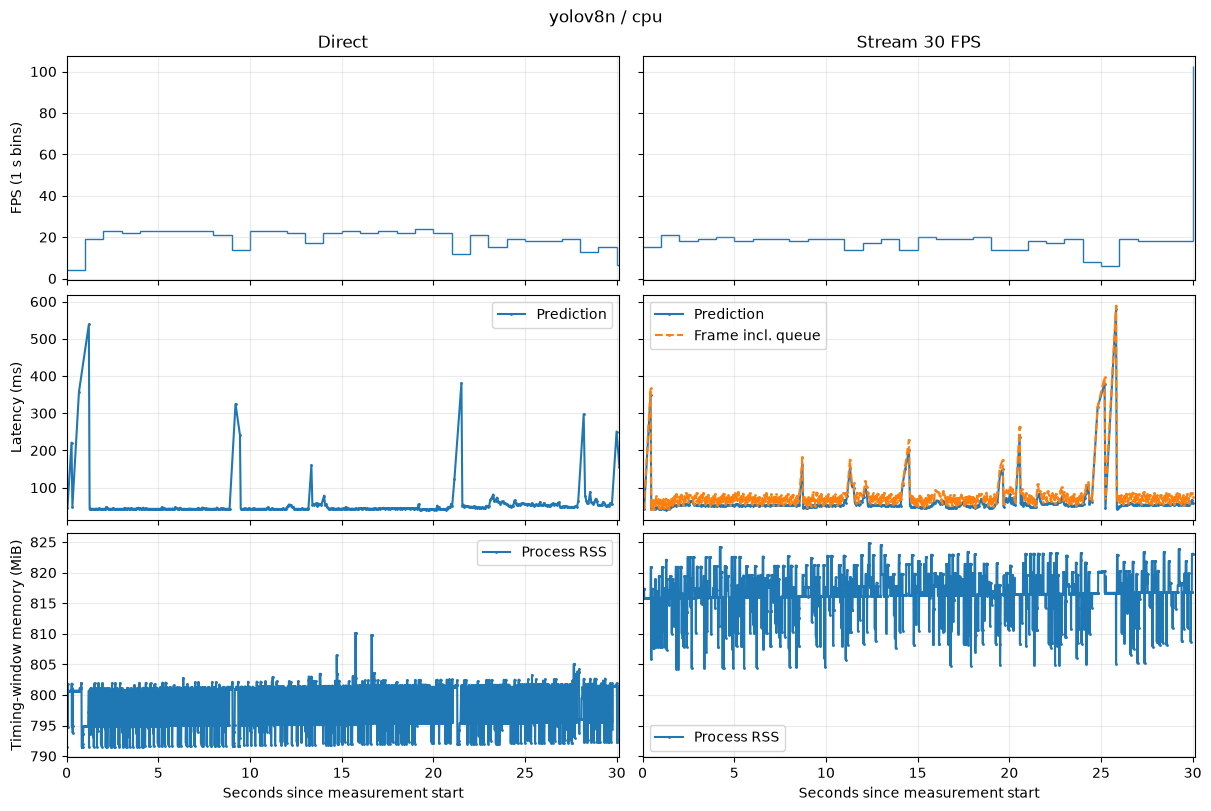

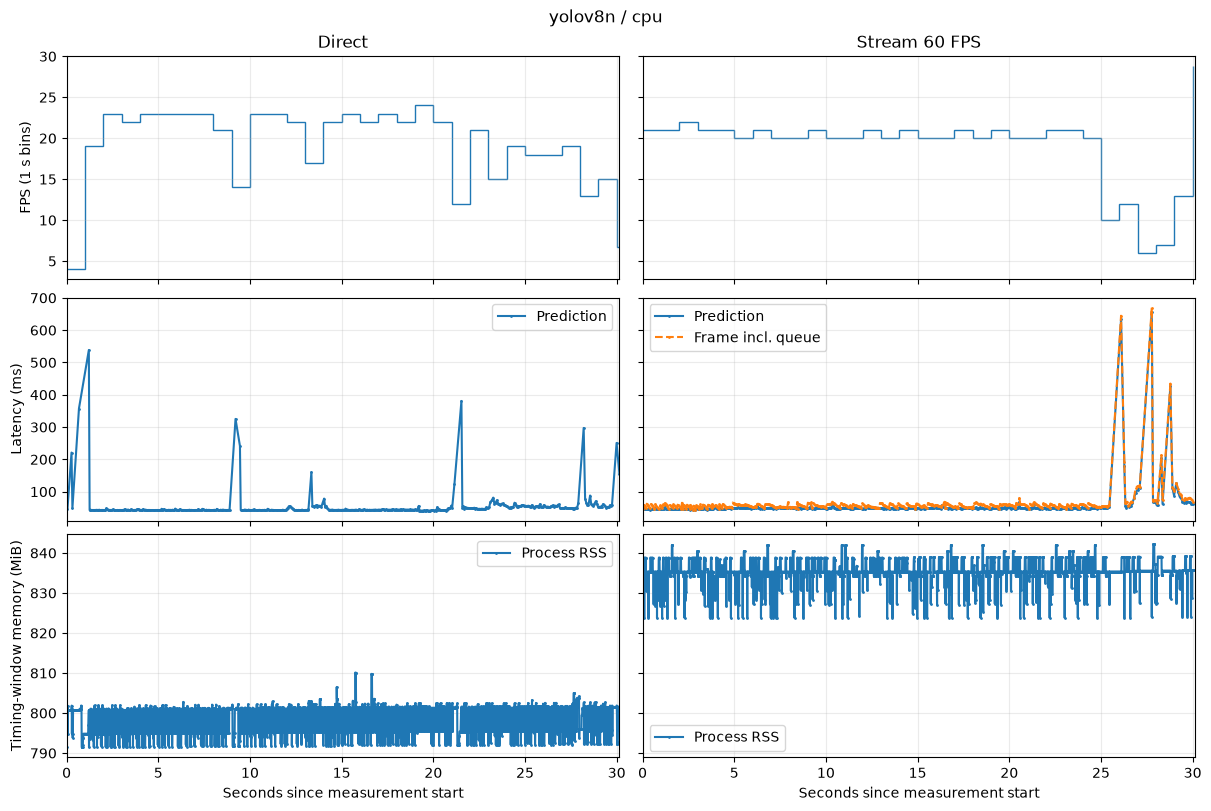

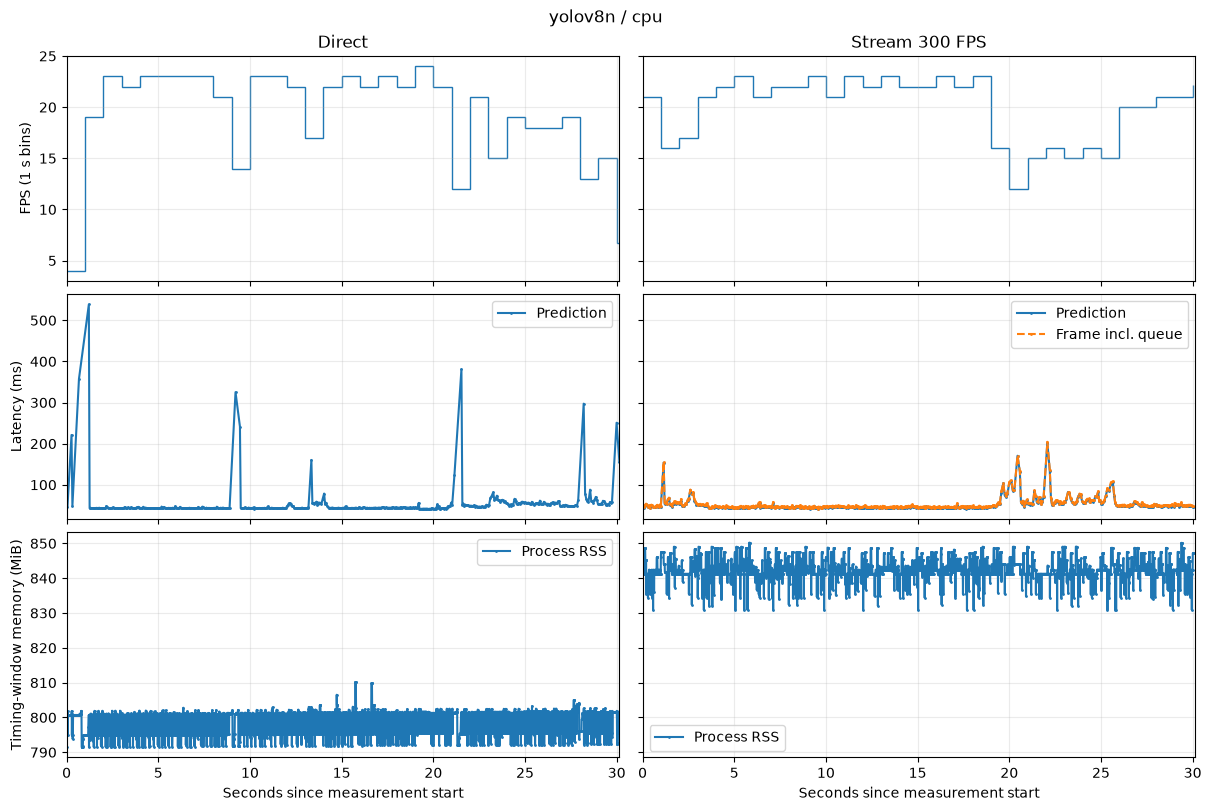

In [4]:
ZERO_BASED_Y = False  # Автомасштаб по данным; True — начинать ось Y с нуля.
FPS_KIND = "binned"  # "binned" или "instantaneous"
FPS_BIN_SECONDS = 1.0  # Ширина окна для binned.

for figure in comparison_figures(measurements, kind=FPS_KIND, bin_seconds=FPS_BIN_SECONDS, zero_based_y=ZERO_BASED_Y):
    display(figure)
    plt.close(figure)